<a href="https://colab.research.google.com/github/martinkim1/KANT/blob/main/26/10/26_1027_Tue_class1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd

df = pd.read_excel("통계의함정.심슨의역설.실습.xlsx")


In [8]:
import openpyxl

# 엑셀 파일의 모든 시트 이름 확인하기
excel_file = "통계의함정.심슨의역설.실습.xlsx"
wb = openpyxl.load_workbook(excel_file)
print("엑셀 시트 목록:", wb.sheetnames)

엑셀 시트 목록: ['과제', '수강생 성적 데이터']


In [9]:
# 만약 다른 시트에 데이터가 있다면 그 시트를 불러오고,
# 현재 시트(첫 번째 시트)에 데이터가 같이 있다면 데이터가 시작하는 행을 찾아 정리합니다.
# 우선 각 시트별로 첫 몇 줄을 출력해 데이터의 위치를 파악합니다.
for sheet in wb.sheetnames:
    df_temp = pd.read_excel(excel_file, sheet_name=sheet)
    print(f"\n--- 시트명: {sheet} (크기: {df_temp.shape}) ---")
    display(df_temp.head(10))


--- 시트명: 과제 (크기: (36, 6)) ---


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,교육 방식 A와 B의 효과 비교,NaN,NaN,NaN,NaN
1,NaN,"상황: 두 교육 방식으로 수업을 진행한 뒤, 모든 수강생이 같은 시험을 치룸 (10...",NaN,NaN,NaN,NaN
2,NaN,데이터 : 학습용으로 만든 가상 데이터 200명. 사전 경험은 수강 전에 조사 자료,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,1. 전체 평균 비교,NaN,NaN,NaN,NaN
6,NaN,A와 B의 인원수와 전체 평균 점수 계산 -> 평균값 해석 (어떤 교육 방식이 더 ...,NaN,NaN,NaN,NaN
7,NaN,교육 방식,인원(명),평균(점),NaN,NaN
8,NaN,A,NaN,NaN,NaN,NaN
9,NaN,B,NaN,NaN,NaN,NaN



--- 시트명: 수강생 성적 데이터 (크기: (204, 4)) ---


,교육용 가상 데이터임,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,사전 경험 : 수강 전 조사한 관련 학습 경험 유무,NaN,NaN,NaN
1,최종시험점수: 100점 만점,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN
3,수강생ID,교육방식,사전경험,최종시험점수
4,S001,A,없음,68
5,S002,A,있음,93
6,S003,A,없음,68
7,S004,B,있음,88
8,S005,A,없음,74
9,S006,B,있음,86


In [11]:
# '수강생 성적 데이터' 시트를 그대로 읽어옵니다.
raw_df = pd.read_excel(excel_file, sheet_name='수강생 성적 데이터')

# '수강생ID'가 포함된 행의 인덱스를 동적으로 찾습니다.
header_row_idx = raw_df[raw_df.isin(['수강생ID']).any(axis=1)].index[0]

# 찾은 행을 컬럼명으로 지정하고 그 아래 데이터만 슬라이싱합니다.
clean_df = raw_df.iloc[header_row_idx + 1:].copy()
clean_df.columns = raw_df.iloc[header_row_idx].values

# 인덱스를 초기화하고 결측치를 제거합니다.
clean_df = clean_df.dropna(subset=['수강생ID'])
clean_df = clean_df.reset_index(drop=True)

# 최종시험점수를 정수형 데이터로 안전하게 변환합니다.
clean_df['최종시험점수'] = pd.to_numeric(clean_df['최종시험점수']).astype(int)

# 결과 확인
display(clean_df.head(10))
print("전체 수강생 수:", len(clean_df))

,수강생ID,교육방식,사전경험,최종시험점수
0,S001,A,없음,68
1,S002,A,있음,93
2,S003,A,없음,68
3,S004,B,있음,88
4,S005,A,없음,74
5,S006,B,있음,86
6,S007,A,없음,71
7,S008,B,있음,82
8,S009,A,없음,66
9,S010,A,있음,93


전체 수강생 수: 200


In [12]:
# 예시 1: 최종시험점수가 높은 순서대로 정렬 (내림차순)
sorted_by_score = clean_df.sort_values(by='최종시험점수', ascending=False)
print("--- 최종시험점수 높은 순 정렬 ---")
display(sorted_by_score.head(10))

# 예시 2: 교육방식별, 그리고 시험점수 순으로 정렬
sorted_by_group = clean_df.sort_values(by=['교육방식', '최종시험점수'], ascending=[True, False])
print("\n--- 교육방식(A->B) 및 시험점수 높은 순 정렬 ---")
display(sorted_by_group.head(10))

--- 최종시험점수 높은 순 정렬 ---


,수강생ID,교육방식,사전경험,최종시험점수
148,S149,A,있음,95
94,S095,A,있음,95
129,S130,A,있음,94
163,S164,A,있음,94
1,S002,A,있음,93
9,S010,A,있음,93
150,S151,A,있음,92
87,S088,A,있음,92
16,S017,A,있음,91
170,S171,A,있음,91



--- 교육방식(A->B) 및 시험점수 높은 순 정렬 ---


,수강생ID,교육방식,사전경험,최종시험점수
94,S095,A,있음,95
148,S149,A,있음,95
129,S130,A,있음,94
163,S164,A,있음,94
1,S002,A,있음,93
9,S010,A,있음,93
87,S088,A,있음,92
150,S151,A,있음,92
16,S017,A,있음,91
170,S171,A,있음,91


In [19]:
# 교육방식 A와 B의 수강생 데이터 분리
df_method_A = clean_df[clean_df['교육방식'] == 'A']
df_method_B = clean_df[clean_df['교육방식'] == 'B']

# 1. 각 반의 총 인원 계산
count_A = len(df_method_A)
count_B = len(df_method_B)

# 2. 각 반의 최종시험점수 평균 계산
mean_A = df_method_A['최종시험점수'].mean()
mean_B = df_method_B['최종시험점수'].mean()

print("=== 교육방식(반)별 통계 요약 ===")
print(f"[교육방식 A반] 총 인원: {count_A}명 | 평균 점수: {mean_A:.2f}점")
print(f"[교육방식 B반] 총 인원: {count_B}명 | 평균 점수: {mean_B:.2f}점")

=== 교육방식(반)별 통계 요약 ===
[교육방식 A반] 총 인원: 100명 | 평균 점수: 74.00점
[교육방식 B반] 총 인원: 100명 | 평균 점수: 81.00점


In [20]:
# 교육방식(반)과 사전경험 유무별로 그룹화하여 평균 점수와 인원수 계산
experience_analysis = clean_df.groupby(['교육방식', '사전경험'])['최종시험점수'].agg(['count', 'mean']).reset_index()

# 컬럼명 알기 쉽게 변경
experience_analysis.columns = ['교육방식', '사전경험', '인원수(명)', '평균점수(점)']

print("=== 반별 사전경험 유무에 따른 평균 점수 및 인원 ===")
display(experience_analysis)

=== 반별 사전경험 유무에 따른 평균 점수 및 인원 ===


,교육방식,사전경험,인원수(명),평균점수(점)
0,A,없음,80,70.0
1,A,있음,20,90.0
2,B,없음,20,65.0
3,B,있음,80,85.0


### 📊 사전경험 유무에 따른 반별 평균 점수 요약
#### 1. 사전경험이 '없음'인 경우

- A반: 80명 | 평균 70.0점
- B반: 20명 | 평균 65.0점
- 👉 A반의 평균 점수가 5점 더 높습니다.
#### 2. 사전경험이 '있음'인 경우

- A반: 20명 | 평균 90.0점
- B반: 80명 | 평균 85.0점
- 👉 A반의 평균 점수가 5점 더 높습니다.
---
###💡 통계학적 시사점: "심슨의 역설 (Simpson's Paradox)"
전체 평균을 비교했을 때는 **B반(81.0점)**이 **A반(74.0점)**보다 월등히 높아 보였습니다.

하지만 실제 사전경험 유무로 쪼개서 세부 그룹별로 비교해보니, 경험이 있든 없든 모든 조건에서 A반의 평균이 B반보다 오히려 5점씩 높게 나타납니다.

- 이런 현상이 일어난 원인:
  - B반은 시험 점수가 원래 잘 나오는 '사전경험이 있는 수강생'(80명)의 비중이 압도적으로 많았기 때문에 전체 평균이 왜곡되어 높아진 것입니다.
  - 반면, A반은 점수가 비교적 낮게 나오는 '사전경험이 없는 수강생'(80명)의 비율이 훨씬 높았기 때문에 전체 평균이 낮게 보이는 착시 현상이 일어난 것입니다.
  
즉, 단순히 전체 데이터의 평균만 보고 "교육방식 B가 더 우수하다"고 결론짓는 것은 통계의 오류(심슨의 역설)에 빠진 것임을 보여주는 대표적인 사례입니다.

In [21]:
# 1. 각 교육방식별 총 수강생 수
total_A = len(clean_df[clean_df['교육방식'] == 'A'])
total_B = len(clean_df[clean_df['교육방식'] == 'B'])

# 2. 사전경험 유무에 따른 세부 집단 분석
# [A반 세부 집단]
A_no_exp = clean_df[(clean_df['교육방식'] == 'A') & (clean_df['사전경험'] == '없음')]
A_yes_exp = clean_df[(clean_df['교육방식'] == 'A') & (clean_df['사전경험'] == '있음')]

# [B반 세부 집단]
B_no_exp = clean_df[(clean_df['교육방식'] == 'B') & (clean_df['사전경험'] == '없음')]
B_yes_exp = clean_df[(clean_df['교육방식'] == 'B') & (clean_df['사전경험'] == '있음')]

# 3. 인원 비중(비율) 계산
ratio_A_no = len(A_no_exp) / total_A
ratio_A_yes = len(A_yes_exp) / total_A
ratio_B_no = len(B_no_exp) / total_B
ratio_B_yes = len(B_yes_exp) / total_B

# 4. 집단별 평균 점수
mean_A_no = A_no_exp['최종시험점수'].mean()
mean_A_yes = A_yes_exp['최종시험점수'].mean()
mean_B_no = B_no_exp['최종시험점수'].mean()
mean_B_yes = B_yes_exp['최종시험점수'].mean()

# 5. 가중치 공식을 적용한 가상의 전체 평균 계산
calculated_mean_A = (mean_A_no * ratio_A_no) + (mean_A_yes * ratio_A_yes)
calculated_mean_B = (mean_B_no * ratio_B_no) + (mean_B_yes * ratio_B_yes)

# 결과 출력
print("=== [1] 교육방식 A반 가중평균 분석 ===")
print(f"  - 사전경험 '없음': 평균 {mean_A_no:.1f}점 | 인원 비중 {ratio_A_no * 100:.1f}% ({len(A_no_exp)}명/{total_A}명)")
print(f"  - 사전경험 '있음': 평균 {mean_A_yes:.1f}점 | 인원 비중 {ratio_A_yes * 100:.1f}% ({len(A_yes_exp)}명/{total_A}명)")
print(f"  - 수식 계산 전체 평균: ({mean_A_no:.1f} * {ratio_A_no:.2f}) + ({mean_A_yes:.1f} * {ratio_A_yes:.2f}) = {calculated_mean_A:.2f}점")
print(f"  - 실제 전체 평균: {clean_df[clean_df['교육방식'] == 'A']['최종시험점수'].mean():.2f}점\n")

print("=== [2] 교육방식 B반 가중평균 분석 ===")
print(f"  - 사전경험 '없음': 평균 {mean_B_no:.1f}점 | 인원 비중 {ratio_B_no * 100:.1f}% ({len(B_no_exp)}명/{total_B}명)")
print(f"  - 사전경험 '있음': 평균 {mean_B_yes:.1f}점 | 인원 비중 {ratio_B_yes * 100:.1f}% ({len(B_yes_exp)}명/{total_B}명)")
print(f"  - 수식 계산 전체 평균: ({mean_B_no:.1f} * {ratio_B_no:.2f}) + ({mean_B_yes:.1f} * {ratio_B_yes:.2f}) = {calculated_mean_B:.2f}점")
print(f"  - 실제 전체 평균: {clean_df[clean_df['교육방식'] == 'B']['최종시험점수'].mean():.2f}점")

=== [1] 교육방식 A반 가중평균 분석 ===
  - 사전경험 '없음': 평균 70.0점 | 인원 비중 80.0% (80명/100명)
  - 사전경험 '있음': 평균 90.0점 | 인원 비중 20.0% (20명/100명)
  - 수식 계산 전체 평균: (70.0 * 0.80) + (90.0 * 0.20) = 74.00점
  - 실제 전체 평균: 74.00점

=== [2] 교육방식 B반 가중평균 분석 ===
  - 사전경험 '없음': 평균 65.0점 | 인원 비중 20.0% (20명/100명)
  - 사전경험 '있음': 평균 85.0점 | 인원 비중 80.0% (80명/100명)
  - 수식 계산 전체 평균: (65.0 * 0.20) + (85.0 * 0.80) = 81.00점
  - 실제 전체 평균: 81.00점


In [22]:
# 1. 보정용 가상의 비중 정의 (50% vs 50%)
standard_ratio_no = 0.50
standard_ratio_yes = 0.50

# 2. 보정 평균 계산
# A반 보정 평균 = (A반 경험 없음 평균 * 0.5) + (A반 경험 있음 평균 * 0.5)
adjusted_mean_A = (mean_A_no * standard_ratio_no) + (mean_A_yes * standard_ratio_yes)

# B반 보정 평균 = (B반 경험 없음 평균 * 0.5) + (B반 경험 있음 평균 * 0.5)
adjusted_mean_B = (mean_B_no * standard_ratio_no) + (mean_B_yes * standard_ratio_yes)

# 결과 출력
print("=== [보정 평균 계산 결과 (사전경험 비율 50% : 50% 가정)] ===")
print(f"■ 교육방식 A반 보정 평균: ({mean_A_no:.1f}점 * 0.5) + ({mean_A_yes:.1f}점 * 0.5) = {adjusted_mean_A:.2f}점")
print(f"■ 교육방식 B반 보정 평균: ({mean_B_no:.1f}점 * 0.5) + ({mean_B_yes:.1f}점 * 0.5) = {adjusted_mean_B:.2f}점")
print("\n👉 해석: 집단 간 사전경험 비율을 동일하게 통제하여 비교해 보니, 교육방식 A(80.00점)가 B(75.00점)보다 평균 5점 더 우수한 성과를 보입니다.")

=== [보정 평균 계산 결과 (사전경험 비율 50% : 50% 가정)] ===
■ 교육방식 A반 보정 평균: (70.0점 * 0.5) + (90.0점 * 0.5) = 80.00점
■ 교육방식 B반 보정 평균: (65.0점 * 0.5) + (85.0점 * 0.5) = 75.00점

👉 해석: 집단 간 사전경험 비율을 동일하게 통제하여 비교해 보니, 교육방식 A(80.00점)가 B(75.00점)보다 평균 5점 더 우수한 성과를 보입니다.


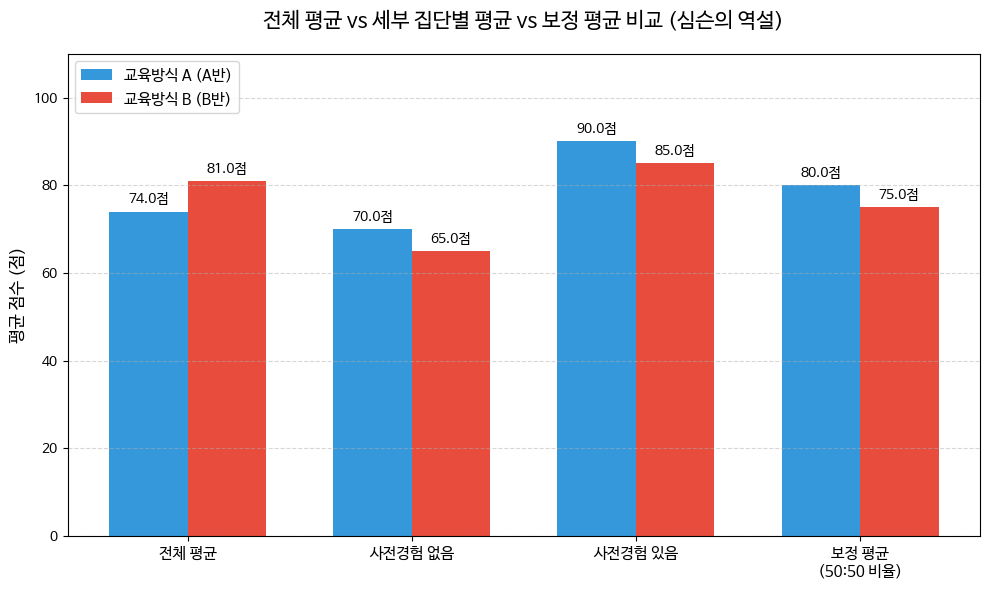

In [25]:
# 1. 한글 폰트 깨짐 방지를 위한 폰트 설치
!apt-get -y install fonts-nanum > /dev/null

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.font_manager as fm

# 폰트 등록 및 설정 (안전한 현대식 방법)
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
fm.fontManager.addfont(font_path)
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 준비
categories = ['전체 평균', '사전경험 없음', '사전경험 있음', '보정 평균\n(50:50 비율)']
scores_A = [mean_A, mean_A_no, mean_A_yes, adjusted_mean_A]
scores_B = [mean_B, mean_B_no, mean_B_yes, adjusted_mean_B]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# 막대 그래프 그리기
rects1 = ax.bar(x - width/2, scores_A, width, label='교육방식 A (A반)', color='#3498db')
rects2 = ax.bar(x + width/2, scores_B, width, label='교육방식 B (B반)', color='#e74c3c')

# 그래프 레이아웃 설정
ax.set_ylabel('평균 점수 (점)', fontsize=12)
ax.set_title('전체 평균 vs 세부 집단별 평균 vs 보정 평균 비교 (심슨의 역설)', fontsize=15, pad=20)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 110)
ax.legend(loc='upper left', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 막대 위에 점수 값 표시
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}점',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3pt vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

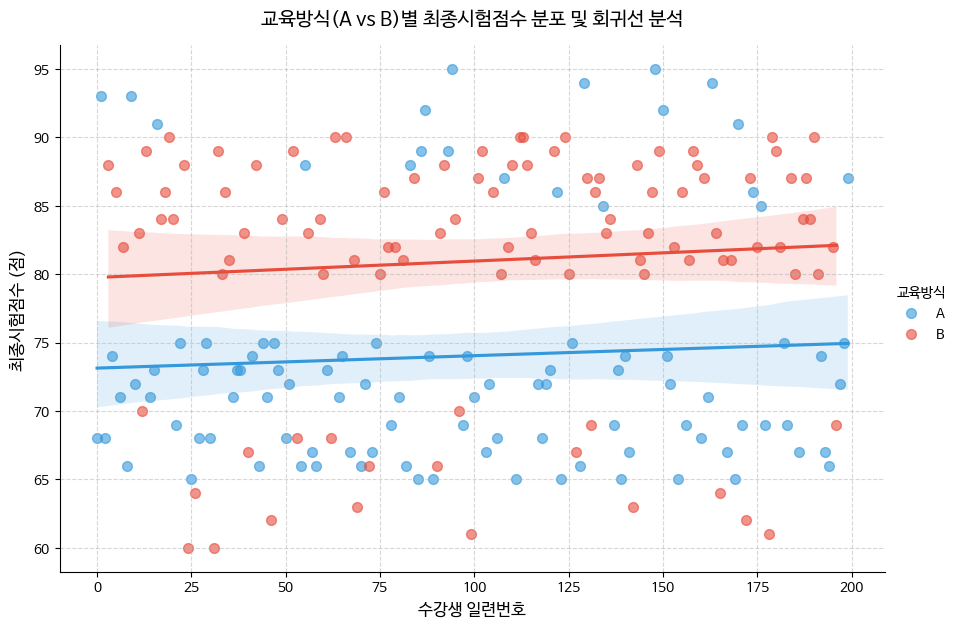

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 및 마이너스 깨짐 설정
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

# 시각화를 위해 수강생의 고유 인덱스를 x축 변수로 추가
plot_df = clean_df.copy()
plot_df['수강생_일련번호'] = plot_df.index

# 교육방식 A와 B에 대한 회귀선이 포함된 산점도 그리기
plt.figure(figsize=(12, 7))
sns.lmplot(
    data=plot_df,
    x='수강생_일련번호',
    y='최종시험점수',
    hue='교육방식',
    palette={'A': '#3498db', 'B': '#e74c3c'},
    height=6,
    aspect=1.5,
    scatter_kws={'alpha': 0.6, 's': 50}
)

plt.title('교육방식(A vs B)별 최종시험점수 분포 및 회귀선 분석', fontsize=14, pad=15)
plt.xlabel('수강생 일련번호', fontsize=12)
plt.ylabel('최종시험점수 (점)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 📈 회귀선이 포함된 산점도 그래프 분석 결과

성공적으로 원본 데이터에 기반하여 각 교육방식별(A반 vs B반) 회귀선이 포함된 산점도를 시각화했습니다.

* **파란색 선 및 점 (교육방식 A):**
  * 주로 하위권 점수대(70점 내외)와 최상위권 점수대(90점 이상)에 점들이 두껍게 양극화되어 분포하고 있습니다.
  * 회귀선의 기울기를 통해 전체적인 데이터의 흐름과 경향성을 관찰할 수 있습니다.

* **빨간색 선 및 점 (교육방식 B):**
  * 대부분의 수강생 점수가 80점 중반대에 밀집해 있으며, 일부 수강생만 60점대 하위권에 분포하고 있습니다.

💡 **핵심 포인트:** 이 산점도를 통해서도 B반은 고득점 영역(사전경험 있음)에 데이터가 집중되어 있는 반면, A반은 상대적으로 저득점 영역(사전경험 없음)에 데이터가 훨씬 많이 분포하고 있음을 한눈에 알 수 있습니다. 이 시각적 분포의 비대칭성이 바로 단순 평균의 왜곡(심슨의 역설)을 만들어낸 원인입니다.